In [10]:
import os
import pandas as pd
import json

DATASET_PATH = "../data/raw/GVLiD/DATASET"
OUTPUT_PATH = "../data/processed/GVLiD_224"

classes = ["healthy", "esca", "Black rot", "leaf blight"]

print("Processed dataset exists:", os.path.exists(OUTPUT_PATH))

Processed dataset exists: True


In [1]:
import pandas as pd
import json

METADATA_PATH = "../data/raw/GVLiD/DATASET/metadata.json"

with open(METADATA_PATH, "r") as file:
    metadata = json.load(file)

print("Total records:", len(metadata))
print("\nFirst record:")
print(metadata[0])

Total records: 3477

First record:
{'Image_ID': 'IMG_0001', 'image_filename': 'black rot001.jpg', 'Location': {'Vineyard': 'Vineyard_22', 'GPS': {'Latitude': 18.785238, 'Longitude': 73.994949}}, 'Environmental_Conditions': {'Time_of_Capture': '2023-06-15T15:13:00+05:30', 'Lighting': 'Overcast', 'Weather': 'Humid'}, 'Plant_Health_Status': 'Diseased', 'Disease_Type': 'Black Rot', 'Device_Specifications': {'Device_Name': 'Redmi Note 10 5G', 'Sensor': 'Sony IMX 582 1/2rr', 'OS': 'Android'}}


In [2]:
df_metadata = pd.json_normalize(metadata)

print("Dataset shape:", df_metadata.shape)
print("\nColumns:")
print(df_metadata.columns.tolist())

Dataset shape: (3477, 13)

Columns:
['Image_ID', 'image_filename', 'Plant_Health_Status', 'Disease_Type', 'Location.Vineyard', 'Location.GPS.Latitude', 'Location.GPS.Longitude', 'Environmental_Conditions.Time_of_Capture', 'Environmental_Conditions.Lighting', 'Environmental_Conditions.Weather', 'Device_Specifications.Device_Name', 'Device_Specifications.Sensor', 'Device_Specifications.OS']


In [3]:
print("Missing values:")
print(df_metadata.isnull().sum())

print("\nDuplicate image filenames:")
print(df_metadata["image_filename"].duplicated().sum())

Missing values:
Image_ID                                    0
image_filename                              0
Plant_Health_Status                         0
Disease_Type                                0
Location.Vineyard                           0
Location.GPS.Latitude                       0
Location.GPS.Longitude                      0
Environmental_Conditions.Time_of_Capture    0
Environmental_Conditions.Lighting           0
Environmental_Conditions.Weather            0
Device_Specifications.Device_Name           0
Device_Specifications.Sensor                0
Device_Specifications.OS                    0
dtype: int64

Duplicate image filenames:
0


In [4]:
vineyard_counts = df_metadata["Location.Vineyard"].value_counts()

print("Unique vineyards:",
      df_metadata["Location.Vineyard"].nunique())

print("\nImages per vineyard:")
print(vineyard_counts)

Unique vineyards: 28

Images per vineyard:
Location.Vineyard
Vineyard_24    144
Vineyard_26    142
Vineyard_23    135
Vineyard_25    134
Vineyard_12    134
Vineyard_11    133
Vineyard_8     130
Vineyard_22    130
Vineyard_6     129
Vineyard_5     127
Vineyard_4     126
Vineyard_9     125
Vineyard_10    125
Vineyard_15    125
Vineyard_27    125
Vineyard_28    124
Vineyard_17    123
Vineyard_3     123
Vineyard_2     122
Vineyard_18    122
Vineyard_21    120
Vineyard_13    117
Vineyard_14    117
Vineyard_19    112
Vineyard_16    109
Vineyard_1     109
Vineyard_20    108
Vineyard_7     107
Name: count, dtype: int64


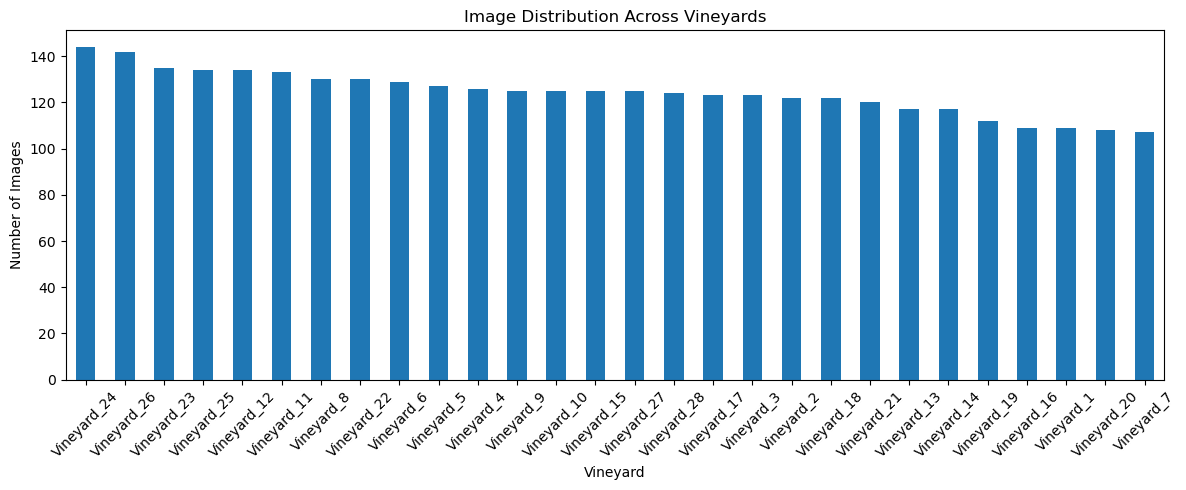

In [5]:
import matplotlib.pyplot as plt

vineyard_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Image Distribution Across Vineyards"
)

plt.xlabel("Vineyard")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
print("Lighting distribution:")
print(df_metadata["Environmental_Conditions.Lighting"].value_counts())

print("\nWeather distribution:")
print(df_metadata["Environmental_Conditions.Weather"].value_counts())

Lighting distribution:
Environmental_Conditions.Lighting
Natural sunlight    1175
Overcast            1164
Partly cloudy       1138
Name: count, dtype: int64

Weather distribution:
Environmental_Conditions.Weather
Windy    1176
Humid    1160
Clear    1141
Name: count, dtype: int64


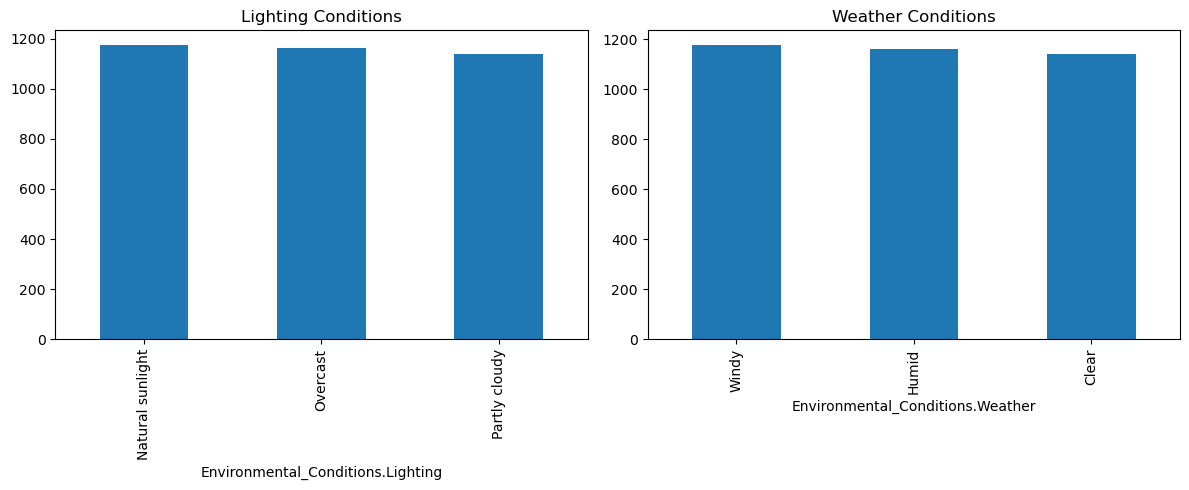

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_metadata["Environmental_Conditions.Lighting"].value_counts().plot(
    kind="bar", ax=axes[0], title="Lighting Conditions"
)

df_metadata["Environmental_Conditions.Weather"].value_counts().plot(
    kind="bar", ax=axes[1], title="Weather Conditions"
)

plt.tight_layout()
plt.show()

In [8]:
df_metadata["Environmental_Conditions.Time_of_Capture"] = pd.to_datetime(
    df_metadata["Environmental_Conditions.Time_of_Capture"]
)

print("First capture:",
      df_metadata["Environmental_Conditions.Time_of_Capture"].min())

print("Last capture:",
      df_metadata["Environmental_Conditions.Time_of_Capture"].max())

print("\nImages captured by year:")
print(
    df_metadata["Environmental_Conditions.Time_of_Capture"]
    .dt.year.value_counts().sort_index()
)

First capture: 2023-06-15 07:30:00+05:30
Last capture: 2023-06-15 20:00:00+05:30

Images captured by year:
Environmental_Conditions.Time_of_Capture
2023    3477
Name: count, dtype: int64


In [12]:
master_df = df_metadata.copy()

def get_image_path(filename):
    for category in classes:
        path = os.path.join(OUTPUT_PATH, category, filename)

        if os.path.isfile(path):
            return path

    return None

master_df["image_path"] = master_df["image_filename"].apply(get_image_path)

# Check for missing processed images
print("Missing processed images:", master_df["image_path"].isna().sum())

# Extract provisional labels from folder names
master_df["label"] = master_df["image_path"].apply(
    lambda x: os.path.basename(os.path.dirname(x))
    if pd.notna(x) else None
)

master_df = master_df.rename(columns={
    "image_filename": "filename",
    "Location.Vineyard": "vineyard_id",
    "Location.GPS.Latitude": "latitude",
    "Location.GPS.Longitude": "longitude",
    "Environmental_Conditions.Time_of_Capture": "timestamp",
    "Environmental_Conditions.Lighting": "lighting",
    "Environmental_Conditions.Weather": "weather"
})

selected_columns = [
    "image_path", "filename", "label",
    "vineyard_id", "latitude", "longitude",
    "timestamp", "lighting", "weather"
]

master_df = master_df[selected_columns]

print("\nMaster dataset shape:", master_df.shape)
print("\nClass distribution:")
print(master_df["label"].value_counts())

print("\nMissing values:")
print(master_df.isnull().sum())

Missing processed images: 0

Master dataset shape: (3477, 9)

Class distribution:
label
healthy        1109
esca            888
Black rot       808
leaf blight     672
Name: count, dtype: int64

Missing values:
image_path     0
filename       0
label          0
vineyard_id    0
latitude       0
longitude      0
timestamp      0
lighting       0
weather        0
dtype: int64


In [13]:
vineyard_class = pd.crosstab(
    master_df["vineyard_id"],
    master_df["label"]
)

print(vineyard_class)

label        Black rot  esca  healthy  leaf blight
vineyard_id                                       
Vineyard_1          14    34       35           26
Vineyard_10         34    37       35           19
Vineyard_11         29    41       39           24
Vineyard_12         33    33       44           24
Vineyard_13         26    29       42           20
Vineyard_14         30    30       39           18
Vineyard_15         21    30       48           26
Vineyard_16         17    28       40           24
Vineyard_17         32    31       37           23
Vineyard_18         29    35       28           30
Vineyard_19         33    31       29           19
Vineyard_2          24    33       40           25
Vineyard_20         33    16       32           27
Vineyard_21         30    29       40           21
Vineyard_22         40    26       29           35
Vineyard_23         32    35       47           21
Vineyard_24         34    40       45           25
Vineyard_25         39    35   

In [14]:
print(
    master_df.groupby("label")["vineyard_id"]
    .nunique()
)

label
Black rot      28
esca           28
healthy        28
leaf blight    28
Name: vineyard_id, dtype: int64


In [15]:
from sklearn.model_selection import GroupShuffleSplit

# First: separate training from temporary data
gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=8,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        master_df,
        groups=master_df["vineyard_id"]
    )
)

train_df = master_df.iloc[train_idx].copy()
temp_df = master_df.iloc[temp_idx].copy()

# Second: separate validation and test
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        groups=temp_df["vineyard_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (2525, 9)
Validation: (490, 9)
Testing: (462, 9)


In [16]:
train_vineyards = set(train_df["vineyard_id"])
val_vineyards = set(val_df["vineyard_id"])
test_vineyards = set(test_df["vineyard_id"])

print("Train-Val overlap:", train_vineyards & val_vineyards)
print("Train-Test overlap:", train_vineyards & test_vineyards)
print("Val-Test overlap:", val_vineyards & test_vineyards)

Train-Val overlap: set()
Train-Test overlap: set()
Val-Test overlap: set()


In [17]:
print("TRAINING")
print(train_df["label"].value_counts())

print("\nVALIDATION")
print(val_df["label"].value_counts())

print("\nTESTING")
print(test_df["label"].value_counts())

TRAINING
label
healthy        815
esca           646
Black rot      581
leaf blight    483
Name: count, dtype: int64

VALIDATION
label
healthy        147
Black rot      124
esca           113
leaf blight    106
Name: count, dtype: int64

TESTING
label
healthy        147
esca           129
Black rot      103
leaf blight     83
Name: count, dtype: int64


In [18]:
import os

SPLIT_PATH = "../data/processed/splits"

os.makedirs(SPLIT_PATH, exist_ok=True)

train_df.to_csv(
    os.path.join(SPLIT_PATH, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(SPLIT_PATH, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(SPLIT_PATH, "test.csv"),
    index=False
)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!


In [19]:
print("Train:", pd.read_csv(
    os.path.join(SPLIT_PATH, "train.csv")
).shape)

print("Validation:", pd.read_csv(
    os.path.join(SPLIT_PATH, "validation.csv")
).shape)

print("Test:", pd.read_csv(
    os.path.join(SPLIT_PATH, "test.csv")
).shape)

Train: (2525, 9)
Validation: (490, 9)
Test: (462, 9)
